# 3장. 수학 기초: 수식을 읽기 위한 최소한

| 항목 | 내용 |
|---|---|
| 예상 시간 | 3시간 |
| 선수 장 | 2장 |
| 이 장의 결과물 | 노름, 내적, 코사인 유사도를 계산하는 순수 파이썬 함수 |
| 관련 학습 목표 | ③ 코사인 유사도가 내적과 정규화로 계산되는 원리 |

**학습 목표**
- 시그마(Σ) 수식을 보고 for 루프로 바꿔 쓸 수 있다.
- 로그의 성질을 알고, 로그가 "큰 차이를 줄인다"는 의미를 숫자로 보여 줄 수 있다.
- 벡터의 길이(L2 노름), 내적, 코사인 유사도를 손과 코드로 계산할 수 있다.
- 코사인 유사도가 문서 길이의 영향을 받지 않는 이유를 설명할 수 있다.
- 행렬 × 벡터가 "모든 문서와 한꺼번에 내적하기"라는 것을 이해한다.

이 장은 NumPy를 쓰지 않고 **순수 파이썬**으로 계산합니다. 원리를 먼저 손으로 익히고, 4장에서 같은 계산을 NumPy 한 줄로 바꿉니다. 그래프는 글꼴 설정(6장) 전이라 축 이름을 영어로 씁니다.

In [1]:
# 미니 코퍼스: 모든 장에서 함께 쓰는 문서 5개 (0장 0.5절 참고)
MINI_DOCS = [
    "The rocket launched into space!",
    "NASA launched a new space telescope.",
    "The pitcher threw a fast ball.",
    "Our team won the baseball game.",
    "Astronauts watched the baseball game in space.",
]
MINI_LABELS = ["space", "space", "baseball", "baseball", "space"]

import math

import matplotlib.pyplot as plt

STOP = {"the", "a", "into", "our", "in", "new"}
FILTERED = [[t for t in doc.lower().strip(".!").split() if t not in STOP] for doc in MINI_DOCS]

## 3.1 시그마(Σ) 읽기

$$\sum_{i=1}^{n} x_i = x_1 + x_2 + \cdots + x_n$$

"$i$를 1부터 $n$까지 바꿔 가며 $x_i$를 모두 더하라"는 뜻입니다. 코드로는 for 루프 하나입니다. 수학은 보통 1부터, 파이썬은 0부터 번호를 매긴다는 점만 주의하세요.

| 수식 | 말로 | 코드 |
|---|---|---|
| $\sum_{i=1}^{n} x_i$ | 모든 원소의 합 | `sum(x)` |
| $\sum_{i=1}^{n} x_i^2$ | 원소를 제곱해서 합 | `sum(v * v for v in x)` |
| $\sum_{i=1}^{n} a_i b_i$ | 같은 위치끼리 곱해서 합 (내적) | `sum(p * q for p, q in zip(a, b))` |
| $\sum_{t \in d} \text{tf}(t, d)$ | 문서 $d$의 모든 단어 $t$에 대해 빈도를 합 (= 문서 길이) | `sum(Counter(d).values())` |

In [2]:
from collections import Counter

x = [3, 1, 4, 1, 5]

total = 0
for i in range(len(x)):    # Σ를 for 루프로
    total += x[i]
print("Σ x_i      :", total, "=", sum(x))
print("Σ x_i^2    :", sum(v * v for v in x))

doc = FILTERED[4]
print("\n문서:", doc)
print("Σ tf(t, d) :", sum(Counter(doc).values()), "= 토큰 수", len(doc))

Σ x_i      : 14 = 14
Σ x_i^2    : 52

문서: ['astronauts', 'watched', 'baseball', 'game', 'space']
Σ tf(t, d) : 5 = 토큰 수 5


**이중 시그마** $\sum_{d=1}^{N} \sum_{t \in d} \text{tf}(t, d)$는 "모든 문서에 대해, 그 문서의 모든 단어 빈도를 합하라"입니다. 이중 for 루프가 되고, 결과는 코퍼스 전체 토큰 수입니다.

In [3]:
print("코퍼스 전체 토큰 수:", sum(sum(Counter(d).values()) for d in FILTERED))

코퍼스 전체 토큰 수: 20


## 3.2 로그

### 정의
$$\log_b x = y \iff b^y = x$$

"$b$를 몇 번 곱해야 $x$가 되는가"입니다. $\log_{10} 1000 = 3$이고 $\log_2 8 = 3$입니다.

- **자연로그** $\ln x = \log_e x$ ($e \approx 2.718$). NumPy의 `np.log`, 파이썬의 `math.log`, sklearn의 IDF는 모두 **자연로그**입니다.
- 밑이 달라도 $\log_b x = \ln x / \ln b$이므로 **상수배 차이**일 뿐입니다.

### 꼭 기억할 성질

| 성질 | 의미 |
|---|---|
| $\log 1 = 0$ | 1의 로그는 0. 모든 문서에 나오는 단어의 IDF가 0이 될 수 있는 이유 |
| $\log(ab) = \log a + \log b$ | 곱셈이 덧셈이 된다 |
| $\log(a/b) = \log a - \log b$ | 나눗셈이 뺄셈이 된다 |
| $x$가 커지면 $\log x$도 커진다 | 크기 순서는 그대로 유지된다 |
| $\log 0$은 정의되지 않음 ($-\infty$) | 0이 들어가지 않도록 $+1$을 더하는 이유 |

In [4]:
print("ln(1)    =", math.log(1))
print("ln(e)    =", math.log(math.e))
print("log10(1000) =", math.log10(1000))
print("ln(2*3) = ln2 + ln3 ?", math.isclose(math.log(6), math.log(2) + math.log(3)))
try:
    math.log(0)
except ValueError as e:
    print("ln(0)    → ValueError:", e)

ln(1)    = 0.0
ln(e)    = 1.0
log10(1000) = 3.0
ln(2*3) = ln2 + ln3 ? True
ln(0)    → ValueError: math domain error


### 로그는 큰 차이를 줄인다
$x$가 10배씩 커질 때 $\ln x$는 약 2.3씩만 커집니다. **곱셈의 차이가 덧셈의 차이로** 바뀌는 것입니다.

      x   ln x
      1   0.00
     10   2.30
    100   4.61
  1,000   6.91
 10,000   9.21


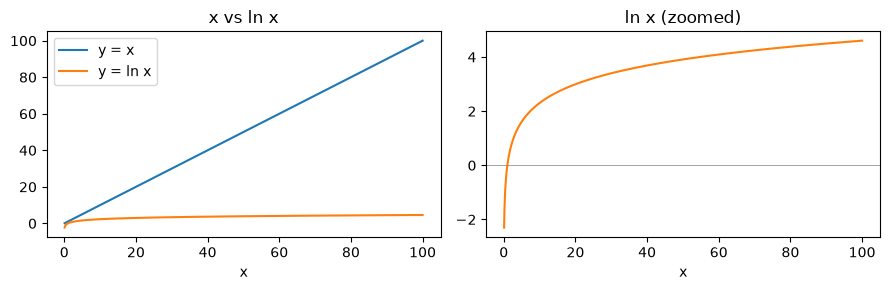

In [5]:
print(f"{'x':>7} {'ln x':>6}")
for v in [1, 10, 100, 1000, 10000]:
    print(f"{v:>7,} {math.log(v):>6.2f}")

xs = [i / 10 for i in range(1, 1001)]
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(xs, xs, label="y = x")
axes[0].plot(xs, [math.log(v) for v in xs], label="y = ln x")
axes[0].set_title("x vs ln x")
axes[0].legend()
axes[1].plot(xs, [math.log(v) for v in xs], color="tab:orange")
axes[1].set_title("ln x (zoomed)")
axes[1].axhline(0, color="gray", lw=0.5)
for ax in axes:
    ax.set_xlabel("x")
plt.tight_layout()
plt.show()

### TF-IDF에서 로그가 쓰이는 두 곳 (12장 미리 보기)

**① IDF**: 문서 $N$개 중 $\text{df}$개 문서에 나온 단어의 희귀도. 로그가 없으면 희귀한 단어 하나가 다른 단어를 압도합니다.

In [6]:
N = 1000
print(f"{'df':>5} {'N/df':>7} {'ln(N/df)':>9} {'ln((1+N)/(1+df))+1':>20}")
for df in [1, 10, 100, 1000]:
    raw = N / df
    print(f"{df:>5} {raw:>7.0f} {math.log(raw):>9.2f} {math.log((1 + N) / (1 + df)) + 1:>20.2f}")

   df    N/df  ln(N/df)   ln((1+N)/(1+df))+1
    1    1000      6.91                 7.22
   10     100      4.61                 5.51
  100      10      2.30                 3.29
 1000       1      0.00                 1.00


- 로그 없이 `N/df`를 쓰면 df=1인 단어가 df=100인 단어보다 **100배** 중요해집니다. 로그를 쓰면 약 1.7배(6.91 / 4.61)입니다.
- df=N, 즉 모든 문서에 나오는 단어는 $\ln 1 = 0$이 되어 완전히 무시됩니다. 오른쪽 열의 **smooth IDF**는 끝에 $+1$을 더해 이런 단어도 최소한의 가중치를 남깁니다(12장에서 자세히).

**② sublinear TF**: 한 문서에서 단어가 100번 나왔다고 1번보다 100배 중요하지는 않다는 생각을 $1 + \ln(\text{tf})$로 표현합니다.

In [7]:
for tf in [1, 2, 10, 100]:
    print(f"tf={tf:>3} → 1 + ln(tf) = {1 + math.log(tf):.2f}")

tf=  1 → 1 + ln(tf) = 1.00
tf=  2 → 1 + ln(tf) = 1.69
tf= 10 → 1 + ln(tf) = 3.30
tf=100 → 1 + ln(tf) = 5.61


## 3.3 벡터와 노름

### 벡터
**벡터**는 순서가 있는 숫자 목록입니다. 어휘가 `[ball, game, rocket, space]`일 때 "the rocket launched into space"의 단어 개수는 벡터 `[0, 0, 1, 1]`로 쓸 수 있습니다. 어휘 크기가 수만 개면 수만 차원 벡터가 됩니다. 이렇게 **문서를 공간 위의 한 점(화살표)**으로 바꾸는 것이 이 과제의 핵심 아이디어입니다.

2차원이면 그림으로 그릴 수 있습니다. 가로축을 `rocket` 개수, 세로축을 `space` 개수라고 생각해 보세요.

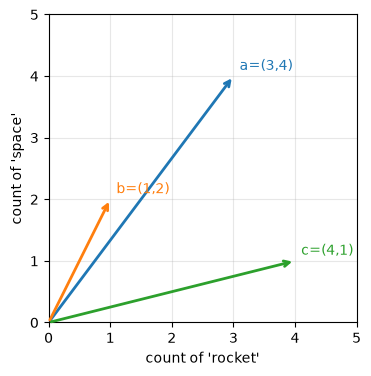

In [8]:
vectors = {"a=(3,4)": (3, 4), "b=(1,2)": (1, 2), "c=(4,1)": (4, 1)}

fig, ax = plt.subplots(figsize=(4, 4))
for (name, (vx, vy)), color in zip(vectors.items(), ["tab:blue", "tab:orange", "tab:green"]):
    ax.annotate("", xy=(vx, vy), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=color, lw=2))
    ax.text(vx + 0.1, vy + 0.1, name, color=color)
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.set_xlabel("count of 'rocket'")
ax.set_ylabel("count of 'space'")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
plt.show()

### 노름: 벡터의 길이

| 이름 | 수식 | (3, 4)의 값 |
|---|---|---|
| **L2 노름** (유클리드 길이) | $\lVert v \rVert_2 = \sqrt{\sum_i v_i^2}$ | $\sqrt{9 + 16} = 5$ |
| L1 노름 | $\lVert v \rVert_1 = \sum_i \lvert v_i \rvert$ | $3 + 4 = 7$ |

L2 노름은 피타고라스 정리 그대로입니다. 앞으로 그냥 "노름"이라고 하면 L2 노름입니다.

In [9]:
def l2_norm(v: list[float]) -> float:
    return math.sqrt(sum(x * x for x in v))


def l1_norm(v: list[float]) -> float:
    return sum(abs(x) for x in v)


print("L2(3,4) =", l2_norm([3, 4]), "| math.hypot:", math.hypot(3, 4))
print("L1(3,4) =", l1_norm([3, 4]))

L2(3,4) = 5.0 | math.hypot: 5.0
L1(3,4) = 7


### 정규화: 길이를 1로 맞추기
벡터를 자기 노름으로 나누면 **방향은 그대로, 길이는 1**인 벡터(단위 벡터)가 됩니다.

$$\hat{v} = \frac{v}{\lVert v \rVert}$$

어떤 문서와, 그 문서를 두 번 이어 붙인 문서를 생각해 봅시다. 단어 개수는 모두 2배가 되지만 **주제는 같습니다**. 정규화하면 둘이 똑같은 벡터가 됩니다. TF-IDF에서 L2 정규화를 하는 이유가 바로 이것입니다(12장).

In [10]:
def normalize(v: list[float]) -> list[float]:
    n = l2_norm(v)
    return [x / n for x in v] if n > 0 else list(v)   # 0 벡터는 나눌 수 없으니 그대로


doc = [0, 0, 1, 2]           # [ball, game, rocket, space] 개수
doc_twice = [0, 0, 2, 4]     # 같은 문서를 두 번 이어 붙임

print("정규화(doc)      :", [round(x, 3) for x in normalize(doc)])
print("정규화(doc_twice):", [round(x, 3) for x in normalize(doc_twice)])
print("정규화 후 길이   :", round(l2_norm(normalize(doc)), 6))

정규화(doc)      : [0.0, 0.0, 0.447, 0.894]
정규화(doc_twice): [0.0, 0.0, 0.447, 0.894]
정규화 후 길이   : 1.0


## 3.4 내적

### 정의
$$a \cdot b = \sum_{i=1}^{n} a_i b_i$$

같은 위치끼리 곱해서 모두 더합니다. 결과는 벡터가 아니라 **숫자 하나**입니다.

### 문서 벡터에서의 의미
단어 개수 벡터에서 $a_i b_i$가 0이 아니려면 **두 문서 모두에 그 단어가 있어야** 합니다. 그래서 내적은 "**두 문서가 공유하는 단어가 얼마나 많고 강한가**"를 잽니다.

In [11]:
def dot(a: list[float], b: list[float]) -> float:
    return sum(x * y for x, y in zip(a, b, strict=True))


vocab4 = ["ball", "game", "rocket", "space"]
doc_a = [0, 0, 1, 2]   # rocket 1, space 2
doc_b = [0, 1, 0, 1]   # game 1, space 1
doc_c = [1, 1, 0, 0]   # ball 1, game 1

for word, x, y in zip(vocab4, doc_a, doc_b):
    print(f"{word:<7} {x} × {y} = {x * y}")
print("a · b =", dot(doc_a, doc_b), "(겹치는 단어 space만 기여)")
print("a · c =", dot(doc_a, doc_c), "(겹치는 단어 없음)")

ball    0 × 0 = 0
game    0 × 1 = 0
rocket  1 × 0 = 0
space   2 × 1 = 2
a · b = 2 (겹치는 단어 space만 기여)
a · c = 0 (겹치는 단어 없음)


### 기하학적 의미
$$a \cdot b = \lVert a \rVert \, \lVert b \rVert \cos\theta$$

$\theta$는 두 화살표 사이의 각도입니다. 방향이 비슷할수록 내적이 큽니다.

### 내적만으로는 부족한 이유
내적은 벡터 **길이에도 비례**합니다. 같은 문서를 10번 이어 붙이면 내적도 10배가 됩니다. 그러면 긴 문서일수록 검색 점수가 높아지는 문제가 생깁니다.

In [12]:
query = [0, 0, 1, 1]               # "rocket space"
doc_long = [x * 10 for x in doc_a] # doc_a를 10번 이어 붙인 문서

print("query · doc_a    =", dot(query, doc_a))
print("query · doc_long =", dot(query, doc_long), "← 주제는 같은데 점수가 10배")

query · doc_a    = 3
query · doc_long = 30 ← 주제는 같은데 점수가 10배


## 3.5 코사인 유사도 ⭐ 학습 목표 ③

내적에서 길이의 영향을 빼려면 두 벡터의 길이로 나누면 됩니다. 위 식을 $\cos\theta$에 대해 정리한 것이 **코사인 유사도**입니다.

$$\cos(a, b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$$

| 각도 | cos 값 | 의미 |
|---|---|---|
| 0° | 1 | 방향이 같다 (단어 비율이 똑같다) |
| 90° | 0 | 직교한다 (**겹치는 단어가 없다**) |
| 180° | −1 | 정반대 방향 |

**단어 개수나 TF-IDF 값은 음수가 없으므로** 두 벡터 사이 각도는 0°~90°이고, 코사인 유사도는 **0~1** 사이입니다.

In [13]:
def cosine(a: list[float], b: list[float]) -> float:
    na, nb = l2_norm(a), l2_norm(b)
    if na == 0 or nb == 0:
        return 0.0          # 0 벡터(예: 어휘에 없는 단어만 있는 쿼리)는 유사도 0으로 둔다
    return dot(a, b) / (na * nb)


print("cos(query, doc_a)    =", round(cosine(query, doc_a), 4))
print("cos(query, doc_long) =", round(cosine(query, doc_long), 4), "← 길이가 달라도 같다")
print("cos(doc_a, doc_c)    =", cosine(doc_a, doc_c), "← 겹치는 단어 없음")

cos(query, doc_a)    = 0.9487
cos(query, doc_long) = 0.9487 ← 길이가 달라도 같다
cos(doc_a, doc_c)    = 0.0 ← 겹치는 단어 없음


### 유클리드 거리와 비교
두 점 사이의 직선 거리 $\lVert a - b \rVert$로 비슷함을 잴 수도 있습니다. 하지만 거리는 길이 차이에 민감해서, **주제가 같아도 길이가 다르면 멀다**고 판단합니다.

In [14]:
def euclidean(a: list[float], b: list[float]) -> float:
    return l2_norm([x - y for x, y in zip(a, b)])


candidates = {"doc_a (같은 주제)": doc_a, "doc_long (같은 주제, 10배 김)": doc_long, "doc_c (다른 주제)": doc_c}
print(f"{'문서':<28} {'코사인':>6} {'거리':>7}")
for name, v in candidates.items():
    print(f"{name:<28} {cosine(query, v):>6.3f} {euclidean(query, v):>7.2f}")

문서                              코사인      거리
doc_a (같은 주제)                 0.949    1.00
doc_long (같은 주제, 10배 김)       0.949   21.02
doc_c (다른 주제)                 0.000    2.00


거리로 보면 `doc_long`이 다른 주제인 `doc_c`보다도 쿼리에서 **멀다**고 나옵니다. 코사인은 `doc_a`와 `doc_long`을 똑같이 보고 `doc_c`는 0으로 봅니다. 문서 검색에서 코사인을 쓰는 이유입니다.

### 정규화된 벡터에서는 내적 = 코사인
$\lVert \hat a \rVert = \lVert \hat b \rVert = 1$이므로

$$\cos(\hat a, \hat b) = \frac{\hat a \cdot \hat b}{1 \times 1} = \hat a \cdot \hat b$$

TF-IDF 벡터를 미리 L2 정규화해 두면, 검색할 때는 **내적만 계산하면 곧 코사인 유사도**입니다. 15장에서 이 성질로 수천 개 문서의 유사도를 한 번에 계산합니다.

In [15]:
print("cos(query, doc_a)            =", round(cosine(query, doc_a), 6))
print("normalize(query)·normalize(a) =", round(dot(normalize(query), normalize(doc_a)), 6))

cos(query, doc_a)            = 0.948683
normalize(query)·normalize(a) = 0.948683


## 3.6 행렬

**행렬**은 숫자를 직사각형으로 배열한 표입니다. 크기는 `(행 수, 열 수)`로 씁니다. 이 과제의 **문서-단어 행렬**은
- **행 하나 = 문서 하나**의 벡터
- **열 하나 = 단어 하나**가 각 문서에 몇 번 나왔는지
- 크기 = `(문서 수, 어휘 수)`. 과제 예시의 `(500, 3247)`은 문서 500개, 어휘 3,247개라는 뜻입니다.

미니 코퍼스로 직접 만들어 봅니다. 화면에 들어가도록 일부 단어만 열로 씁니다.

In [16]:
cols = ["ball", "baseball", "game", "launched", "rocket", "space", "team"]
matrix = [[Counter(doc)[w] for w in cols] for doc in FILTERED]

print(f"{'':<6}" + "".join(f"{w:>9}" for w in cols))
for doc_id, row in enumerate(matrix):
    print(f"doc {doc_id:<2}" + "".join(f"{v:>9}" for v in row))
print("\nshape:", (len(matrix), len(matrix[0])))

           ball baseball     game launched   rocket    space     team
doc 0         0        0        0        1        1        1        0
doc 1         0        0        0        1        0        1        0
doc 2         1        0        0        0        0        0        0
doc 3         0        1        1        0        0        0        1
doc 4         0        1        1        0        0        1        0

shape: (5, 7)


- **행 방향으로 읽기**: doc 4는 `baseball`, `game`, `space`를 가진 문서입니다.
- **열 방향으로 읽기**: `space` 열에서 0이 아닌 칸이 3개이므로 DF(문서 빈도)가 3입니다. IDF는 이렇게 열 방향으로 계산합니다.

### 행렬 × 벡터 = 모든 행과 한꺼번에 내적
$$X q = \begin{bmatrix} x_1 \cdot q \\ x_2 \cdot q \\ \vdots \\ x_m \cdot q \end{bmatrix}$$

`(m, n)` 행렬에 길이 `n`인 벡터를 곱하면, 각 행과 벡터의 내적을 모은 **길이 `m`인 벡터**가 됩니다. 열 개수와 벡터 길이(`n`)가 같아야 곱할 수 있습니다. 문서-단어 행렬에 쿼리 벡터를 곱하면 **모든 문서의 점수가 한 번에** 나옵니다.

In [17]:
def matvec(X: list[list[float]], q: list[float]) -> list[float]:
    return [dot(row, q) for row in X]


q = [Counter(["space", "rocket"])[w] for w in cols]   # 쿼리 "space rocket"을 같은 열 순서로
print("쿼리 벡터:", q)
print("X · q     :", matvec(matrix, q), "← 문서별 점수")

쿼리 벡터: [0, 0, 0, 0, 1, 1, 0]
X · q     : [2, 1, 0, 0, 1] ← 문서별 점수


4장에서는 이 `matvec`을 NumPy의 `X @ q` 한 줄로 바꾸고, 수천 개 문서에서도 순식간에 계산합니다.

## 📌 핵심 공식 정리

| 이름 | 수식 | 이 과제에서 |
|---|---|---|
| L2 노름 | $\lVert v \rVert = \sqrt{\sum_i v_i^2}$ | TF-IDF 벡터 정규화 |
| 정규화 | $\hat v = v / \lVert v \rVert$ | 문서 길이 영향 제거 |
| 내적 | $a \cdot b = \sum_i a_i b_i$ | 공유 단어의 강도 |
| 코사인 유사도 | $\dfrac{a \cdot b}{\lVert a \rVert \lVert b \rVert}$ | 검색 점수 |
| 정규화된 벡터의 코사인 | $\hat a \cdot \hat b$ | 검색을 행렬곱 한 번으로 |
| 행렬 × 벡터 | `(m, n) × (n,) → (m,)` | 모든 문서 점수 한 번에 |

## ✍️ 실습 1: 손계산

먼저 **종이에** 계산하고, 그다음 위에서 만든 함수로 확인하세요.

$a = (3, 4)$, $b = (6, 8)$, $c = (4, -3)$, $d = (1, 0)$일 때

1. $\lVert a \rVert$, $\lVert b \rVert$
2. $a \cdot b$, $a \cdot c$
3. $\cos(a, b)$, $\cos(a, c)$, $\cos(a, d)$
4. $b$는 $a$와 어떤 관계이고, 그래서 $\cos(a, b)$가 어떻게 나왔나요?

In [18]:
# 여기에 작성하세요

**정답**

In [19]:
a, b, c, d = [3, 4], [6, 8], [4, -3], [1, 0]

print("‖a‖ =", l2_norm(a), " ‖b‖ =", l2_norm(b))          # 5, 10
print("a·b =", dot(a, b), " a·c =", dot(a, c))             # 3*6+4*8=50, 3*4+4*(-3)=0
print("cos(a,b) =", cosine(a, b))                          # 50 / (5*10) = 1
print("cos(a,c) =", cosine(a, c))                          # 0 / ... = 0 (직교)
print("cos(a,d) =", cosine(a, d))                          # 3 / (5*1) = 0.6

‖a‖ = 5.0  ‖b‖ = 10.0
a·b = 50  a·c = 0
cos(a,b) = 1.0
cos(a,c) = 0.0
cos(a,d) = 0.6


4번: $b = 2a$로 **방향이 같고 길이만 2배**입니다. 그래서 코사인 유사도는 1입니다. "같은 문서를 두 번 이어 붙여도 유사도는 같다"와 같은 이야기입니다.

## ✍️ 실습 2: 미니 코퍼스에서 가장 비슷한 문서 찾기

`FILTERED`(불용어를 뺀 미니 코퍼스)로
1. 전체 어휘를 알파벳 순으로 만들고,
2. 각 문서를 단어 개수 벡터로 바꾼 뒤,
3. doc 0과 나머지 문서들의 코사인 유사도를 구해 높은 순으로 출력하세요.

doc 0과 가장 비슷한 문서는 무엇이고, 그 이유는 어떤 단어 때문인가요?

In [20]:
# 여기에 작성하세요

**정답**

In [21]:
vocab = sorted({t for doc in FILTERED for t in doc})
vectors = [[Counter(doc)[w] for w in vocab] for doc in FILTERED]

print("doc 0:", FILTERED[0])
sims = [(cosine(vectors[0], vectors[i]), i) for i in range(1, len(vectors))]
for sim, i in sorted(sims, key=lambda x: (-x[0], x[1])):
    shared = sorted(set(FILTERED[0]) & set(FILTERED[i]))
    print(f"  doc {i}: {sim:.3f}  공유 단어 {shared}")

doc 0: ['rocket', 'launched', 'space']
  doc 1: 0.577  공유 단어 ['launched', 'space']
  doc 4: 0.258  공유 단어 ['space']
  doc 2: 0.000  공유 단어 []
  doc 3: 0.000  공유 단어 []


doc 1이 가장 비슷합니다. `launched`와 `space` 두 단어를 공유하기 때문입니다. 손으로 확인하면 doc 0은 단어 3개, doc 1은 4개(모두 1번씩)이므로 $\cos = 2 / (\sqrt{3}\sqrt{4}) \approx 0.577$입니다. 야구 경기 이야기가 섞인 doc 4도 `space` 하나로 0보다 큰 유사도를 받습니다.

## 🧐 퀴즈

**Q1.** $\ln 1$은 얼마인가요? IDF 식 $\ln\frac{1+N}{1+\text{df}}$에서 분자와 분모에 1을 더하는 이유는?
<details><summary>▶ 정답 보기</summary>

$\ln 1 = 0$입니다. 1을 더하는 이유는 df가 0일 때(학습 문서에 없던 단어) 0으로 나누는 것을 막기 위해서입니다. "모든 문서에 한 번씩 나오는 가상의 문서가 하나 더 있다"고 생각하는 것과 같습니다. 끝에 붙는 $+1$은 모든 문서에 나오는 단어의 IDF가 0이 되지 않도록 합니다(12장).
</details>

**Q2.** 문서 벡터의 모든 값을 3배로 바꾸면 쿼리와의 내적과 코사인 유사도는 각각 어떻게 되나요?
<details><summary>▶ 정답 보기</summary>

내적은 3배가 되고, 코사인 유사도는 변하지 않습니다. 코사인은 길이로 나눠서 방향만 비교하기 때문입니다.
</details>

**Q3.** 두 TF-IDF 벡터의 코사인 유사도가 정확히 0입니다. 두 문서에 대해 무엇을 알 수 있나요?
<details><summary>▶ 정답 보기</summary>

두 문서가 **공유하는 단어가 하나도 없다**는 뜻입니다. TF-IDF 값은 음수가 없으므로, 내적이 0이려면 모든 위치에서 둘 중 하나가 0이어야 합니다. 의미가 비슷해도 단어가 다르면(동의어) 0이 나온다는 BoW의 한계로 이어집니다(21장).
</details>

**Q4.** `(500, 3247)` 크기의 문서-단어 행렬에 길이 3247인 쿼리 벡터를 곱하면 결과의 크기와 의미는?
<details><summary>▶ 정답 보기</summary>

길이 500인 벡터입니다. 500개 문서 각각과 쿼리의 내적(정규화되어 있다면 코사인 유사도)입니다.
</details>

**Q5.** 벡터를 미리 L2 정규화해 두면 검색 때 무엇이 편해지나요?
<details><summary>▶ 정답 보기</summary>

정규화된 벡터끼리는 내적이 곧 코사인 유사도이므로, 노름을 매번 다시 계산하고 나눌 필요 없이 행렬 × 벡터 한 번으로 모든 문서의 유사도를 구할 수 있습니다.
</details>

## ✅ 체크포인트
- [ ] Σ 수식을 for 루프로 바꿔 쓸 수 있다.
- [ ] 로그가 큰 차이를 줄인다는 것을 숫자 예로 보여 줄 수 있다.
- [ ] $(3,4)$의 노름, 두 벡터의 내적, 코사인 유사도를 손으로 계산할 수 있다.
- [ ] 코사인 유사도가 문서 길이에 영향을 받지 않는 이유를 설명할 수 있다.
- [ ] "정규화된 벡터의 내적 = 코사인 유사도"를 한 줄로 증명할 수 있다.

## 🔗 과제 연결과 다음 장
- 학습 목표 ③ "코사인 유사도가 벡터의 내적과 정규화로 계산되는 원리"의 수학적 바탕을 이 장에서 다뤘습니다. 15장에서 NumPy 구현과 함께 완성합니다.
- 로그와 정규화는 12장 TF-IDF 수식에, 행렬 × 벡터는 15장 일괄 검색에 쓰입니다.
- **4장. NumPy 기초**에서 이 장의 `l2_norm`, `dot`, `cosine`, `matvec`를 루프 없는 NumPy 코드로 바꿉니다.